<a href="https://colab.research.google.com/github/Gourikrishna10/Casestusy2-/blob/main/casestudy2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/drive/MyDrive/ICT AI ML/dataset/House_Pricing.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   ID                                         21613 non-null  int64  
 1   Date House was Sold                        21613 non-null  object 
 2   Sale Price                                 21609 non-null  float64
 3   No of Bedrooms                             21613 non-null  int64  
 4   No of Bathrooms                            21609 non-null  float64
 5   Flat Area (in Sqft)                        21604 non-null  float64
 6   Lot Area (in Sqft)                         21604 non-null  float64
 7   No of Floors                               21613 non-null  float64
 8   Waterfront View                            21613 non-null  object 
 9   No of Times Visited                        2124 non-null   object 
 10  Condition of the House

In [2]:
df.describe()

,ID,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft)
count,2.161300e+04,2.160900e+04,21613.000000,21609.000000,21604.000000,2.160400e+04,21613.000000,21613.000000,21610.000000,21613.000000,21613.000000,21613.000000,21612.000000,21612.000000,21612.000000,21612.000000,21613.000000
mean,4.580302e+09,5.401984e+05,3.370842,2.114732,2079.931772,1.510776e+04,1.494309,7.623467,1788.344193,291.509045,46.994864,84.402258,98077.937766,47.560048,-122.213892,1986.538914,12768.455652
std,2.876566e+09,3.673890e+05,0.930062,0.770138,918.487597,4.142827e+04,0.539989,1.105439,827.982604,442.575043,29.373411,401.679240,53.505425,0.138565,0.140830,685.404255,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,1.000000,290.000000,0.000000,3.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1429.250000,5.040000e+03,1.000000,7.000000,1190.000000,0.000000,21.000000,0.000000,98033.000000,47.470975,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.617500e+03,1.500000,7.000000,1560.000000,0.000000,43.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068825e+04,2.000000,8.000000,2210.000000,560.000000,67.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,10.000000,9410.000000,4820.000000,118.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [3]:
df.describe(include="object")

,Date House was Sold,Waterfront View,No of Times Visited,Condition of the House
count,21613,21613,2124,21613
unique,13,2,4,5
top,15 April 2016,No,Twice,Fair
freq,2231,21450,963,14031


In [4]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [5]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Sale Price                                       4
No of Bathrooms                                  4
Flat Area (in Sqft)                              9
Lot Area (in Sqft)                               9
No of Times Visited                          19489
Area of the House from Basement (in Sqft)        3
Zipcode                                          1
Latitude                                         1
Longitude                                        1
Living Area after Renovation (in Sqft)           1
dtype: int64


In [6]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(
    missing_percentage[missing_percentage > 0]
    .sort_values(ascending=False)
)

No of Times Visited                          90.172581
Flat Area (in Sqft)                           0.041642
Lot Area (in Sqft)                            0.041642
Sale Price                                    0.018507
No of Bathrooms                               0.018507
Area of the House from Basement (in Sqft)     0.013881
Zipcode                                       0.004627
Latitude                                      0.004627
Longitude                                     0.004627
Living Area after Renovation (in Sqft)        0.004627
dtype: float64


In [7]:
df = df.dropna(subset=["Sale Price"])

In [8]:
print(df["Sale Price"].isnull().sum())

0


In [9]:
print(df["No of Times Visited"].dtype)
print(df["No of Times Visited"].value_counts(dropna=False))

object
No of Times Visited
NaN       19485
Twice       963
Thrice      510
Once        332
Four        319
Name: count, dtype: int64


In [10]:
mode_value = df["No of Times Visited"].mode()[0]
print(mode_value)

Twice


In [11]:
df["No of Times Visited"] = df["No of Times Visited"].fillna(mode_value)

In [12]:
print(df["No of Times Visited"].isnull().sum())

0


In [13]:
visit_mapping = {
    "Once": 1,
    "Twice": 2,
    "Thrice": 3,
    "Four": 4
}

df["No of Times Visited"] = df["No of Times Visited"].map(visit_mapping)

In [14]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['ID', 'Sale Price', 'No of Bedrooms', 'No of Bathrooms', 'Flat Area (in Sqft)', 'Lot Area (in Sqft)', 'No of Floors', 'No of Times Visited', 'Overall Grade', 'Area of the House from Basement (in Sqft)', 'Basement Area (in Sqft)', 'Age of House (in Years)', 'Renovated Year', 'Zipcode', 'Latitude', 'Longitude', 'Living Area after Renovation (in Sqft)', 'Lot Area after Renovation (in Sqft)']

Categorical columns:
['Date House was Sold', 'Waterfront View', 'Condition of the House']


In [15]:
print(df[categorical_cols].isnull().sum())

Date House was Sold       0
Waterfront View           0
Condition of the House    0
dtype: int64


In [16]:
# Fill missing values in numerical columns with median

for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

In [17]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


In [18]:
numeric_features = [
    col for col in numeric_cols
    if col != "Sale Price"
]

In [19]:
for col in numeric_features:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

In [20]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Sale Price"])
y = df["Sale Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (17287, 20)
X_test: (4322, 20)
y_train: (17287,)
y_test: (4322,)


In [21]:
categorical_cols = [
    "Date House was Sold",
    "Waterfront View",
    "Condition of the House"
]

In [22]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(X_train[col].unique())


Date House was Sold:
['14 May 2017' '14 October 2017' '14 June 2017' '14 July 2017'
 '14 August 2017' '15 March 2016' '14 September 2017' '15 April 2016'
 '15 February 2016' '15 January 2016' '15 May 2016' '14 December 2017'
 '14 November 2017']

Waterfront View:
['No' 'Yes']

Condition of the House:
['Good' 'Fair' 'Okay' 'Excellent' 'Bad']


In [23]:
X_train["Date House was Sold"] = pd.to_datetime(
    X_train["Date House was Sold"]
)

X_test["Date House was Sold"] = pd.to_datetime(
    X_test["Date House was Sold"]
)

In [24]:
for df_part in [X_train, X_test]:
    df_part["Sale_Year"] = df_part["Date House was Sold"].dt.year
    df_part["Sale_Month"] = df_part["Date House was Sold"].dt.month
    df_part["Sale_Day"] = df_part["Date House was Sold"].dt.day

In [25]:
X_train = X_train.drop(columns=["Date House was Sold"])
X_test = X_test.drop(columns=["Date House was Sold"])

In [26]:
condition_mapping = {
    "Bad": 1,
    "Fair": 2,
    "Okay": 3,
    "Good": 4,
    "Excellent": 5
}

X_train["Condition of the House"] = (
    X_train["Condition of the House"].map(condition_mapping)
)

X_test["Condition of the House"] = (
    X_test["Condition of the House"].map(condition_mapping)
)

In [27]:
X_train["Waterfront View"] = X_train["Waterfront View"].map({
    "No": 0,
    "Yes": 1
})

X_test["Waterfront View"] = X_test["Waterfront View"].map({
    "No": 0,
    "Yes": 1
})

In [28]:
from sklearn.preprocessing import StandardScaler

# Numerical feature columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print(numeric_features)

['ID', 'No of Bedrooms', 'No of Bathrooms', 'Flat Area (in Sqft)', 'Lot Area (in Sqft)', 'No of Floors', 'Waterfront View', 'No of Times Visited', 'Condition of the House', 'Overall Grade', 'Area of the House from Basement (in Sqft)', 'Basement Area (in Sqft)', 'Age of House (in Years)', 'Renovated Year', 'Zipcode', 'Latitude', 'Longitude', 'Living Area after Renovation (in Sqft)', 'Lot Area after Renovation (in Sqft)']


In [29]:
scaler = StandardScaler()

X_train[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

X_test[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

In [30]:
X_train[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
ID,17287.0,-4.110272e-19,1.000029,-1.593828,-0.854335,-0.234674,0.948824,1.850779
No of Bedrooms,17287.0,8.343852e-17,1.000029,-3.581736,-0.391594,-0.391594,0.671787,31.509827
No of Bathrooms,17287.0,-9.864653e-18,1.000029,-2.731590,-0.788739,0.182687,0.506495,7.630283
Flat Area (in Sqft),17287.0,-2.046915e-16,1.000029,-1.853635,-0.710710,-0.188230,0.508409,12.481906
Lot Area (in Sqft),17287.0,-5.548867e-18,1.000029,-0.351470,-0.242197,-0.179812,-0.106383,39.589268
No of Floors,17287.0,-4.767916e-17,1.000029,-0.914887,-0.914887,0.008547,0.931981,3.702284
Waterfront View,17287.0,-3.072428e-17,1.000029,-0.084653,-0.084653,-0.084653,-0.084653,11.812905
No of Times Visited,17287.0,1.138545e-16,1.000029,-3.398555,-0.121147,-0.121147,-0.121147,6.433670
Condition of the House,17287.0,-1.623557e-16,1.000029,-1.630935,-0.707965,-0.707965,1.137976,2.060946
Overall Grade,17287.0,1.504360e-16,1.000029,-5.106945,-0.561297,-0.561297,0.347833,2.166092


In [34]:
# Calculate Q1 and Q3 using exactly the continuous columns
Q1 = X_train[continuous_cols].quantile(0.25)
Q3 = X_train[continuous_cols].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outlier_mask = (
    (X_train[continuous_cols] < lower_bound) |
    (X_train[continuous_cols] > upper_bound)
)

# Count outliers in each column
outlier_counts = outlier_mask.sum()

print("Outliers in each column:")
print(outlier_counts.sort_values(ascending=False))

Outliers in each column:
Lot Area (in Sqft)                           1965
Lot Area after Renovation (in Sqft)          1768
Area of the House from Basement (in Sqft)     509
Flat Area (in Sqft)                           461
Basement Area (in Sqft)                       453
Living Area after Renovation (in Sqft)        396
No of Bathrooms                               215
Longitude                                     202
Latitude                                        1
dtype: int64


In [35]:
# Keep rows that are NOT outliers in any continuous feature
keep_mask = ~outlier_mask.any(axis=1)

X_train = X_train.loc[keep_mask].copy()
y_train = y_train.loc[keep_mask].copy()

print("Rows after outlier removal:", X_train.shape[0])
print("Rows removed:", (~keep_mask).sum())

Rows after outlier removal: 14264
Rows removed: 3023


In [36]:
continuous_cols = [
    "Lot Area (in Sqft)",
    "Lot Area after Renovation (in Sqft)",
    "Area of the House from Basement (in Sqft)",
    "Flat Area (in Sqft)",
    "Basement Area (in Sqft)",
    "Living Area after Renovation (in Sqft)",
    "No of Bathrooms",
    "Latitude",
    "Longitude"
]

In [37]:
for col in continuous_cols:
    outliers = X_train[
        (X_train[col] < lower_bound[col]) |
        (X_train[col] > upper_bound[col])
    ]

    print(col, ":", len(outliers))

Lot Area (in Sqft) : 0
Lot Area after Renovation (in Sqft) : 0
Area of the House from Basement (in Sqft) : 0
Flat Area (in Sqft) : 0
Basement Area (in Sqft) : 0
Living Area after Renovation (in Sqft) : 0
No of Bathrooms : 0
Latitude : 0
Longitude : 0


In [38]:
outlier_counts = (
    (X_train[continuous_cols] < lower_bound) |
    (X_train[continuous_cols] > upper_bound)
).sum()

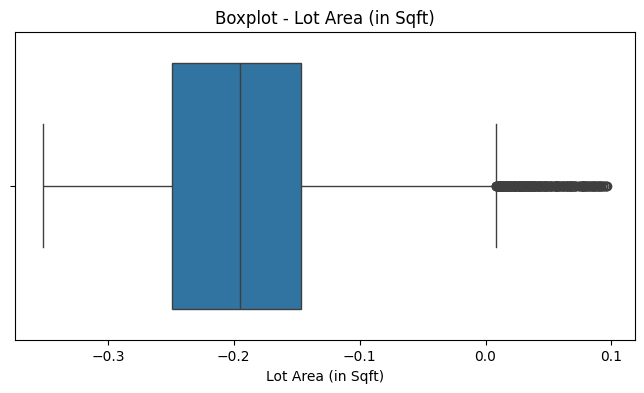

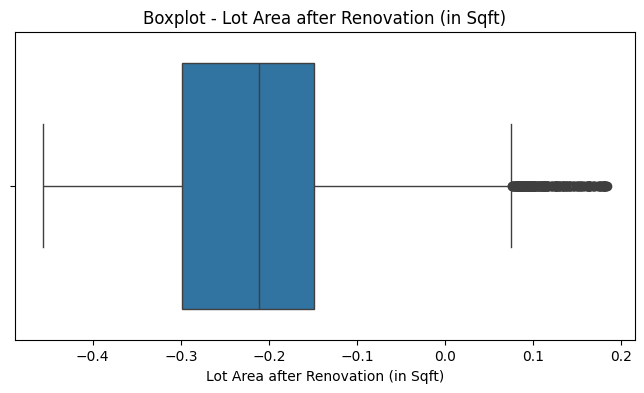

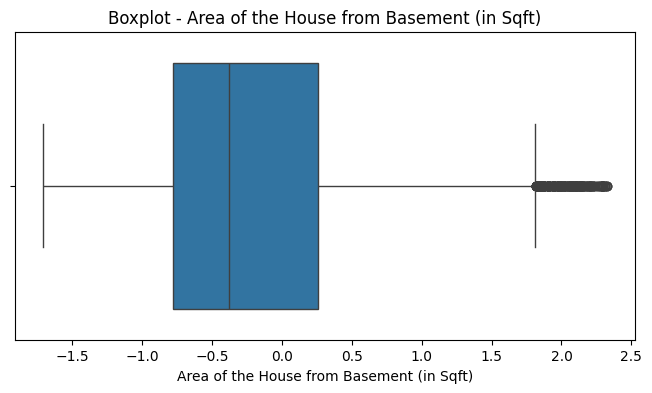

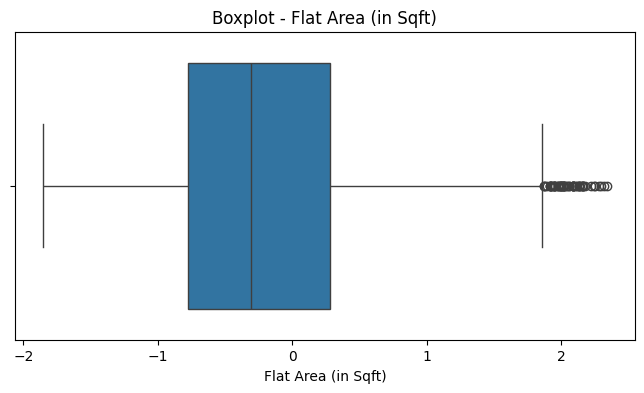

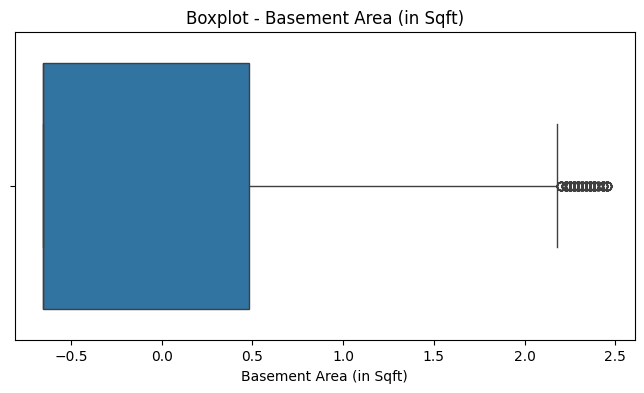

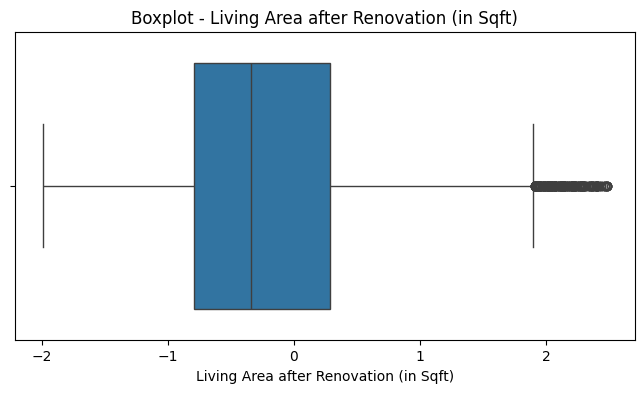

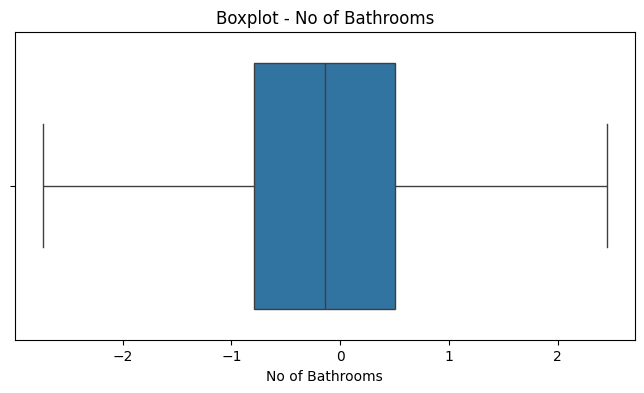

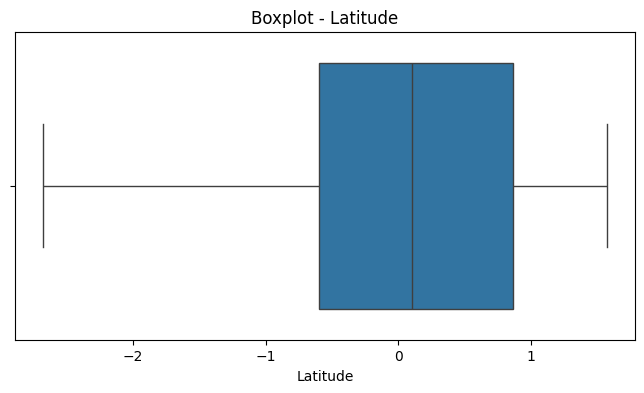

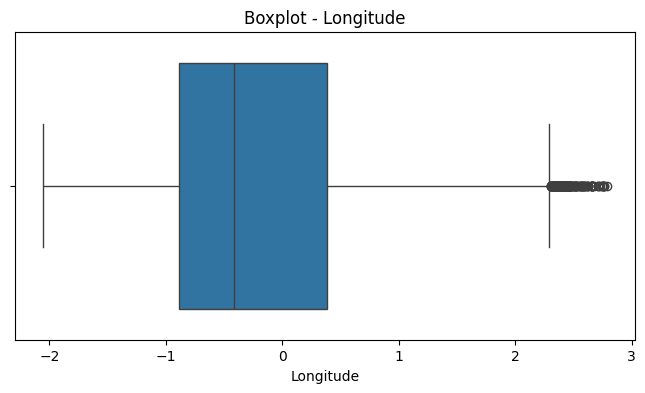

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in continuous_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=X_train[col])
    plt.title(f"Boxplot - {col}")
    plt.show()

In [40]:
print("Rows after outlier removal:", X_train.shape[0])
print("Columns:", X_train.shape[1])

Rows after outlier removal: 14264
Columns: 22


In [41]:
print(X_train[numeric_features].mean().round(2))
print(X_train[numeric_features].std().round(2))

ID                                           0.05
No of Bedrooms                              -0.08
No of Bathrooms                             -0.13
Flat Area (in Sqft)                         -0.21
Lot Area (in Sqft)                          -0.19
No of Floors                                -0.02
Waterfront View                             -0.05
No of Times Visited                         -0.07
Condition of the House                      -0.00
Overall Grade                               -0.14
Area of the House from Basement (in Sqft)   -0.19
Basement Area (in Sqft)                     -0.09
Age of House (in Years)                      0.05
Renovated Year                              -0.02
Zipcode                                      0.09
Latitude                                     0.01
Longitude                                   -0.15
Living Area after Renovation (in Sqft)      -0.19
Lot Area after Renovation (in Sqft)         -0.22
dtype: float64
ID                                 

In [42]:
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print(y_train.head())
print(y_test.head())

Training target shape: (14264,)
Testing target shape: (4322,)
7095     700000.0
18538    410000.0
20023    240000.0
6254     409124.0
15383    330000.0
Name: Sale Price, dtype: float64
4984     570000.0
10256    720001.0
4046     267000.0
21269    365000.0
10496    397000.0
Name: Sale Price, dtype: float64


In [43]:
print("Final Training Data:")
print(X_train.shape)

print("\nFinal Testing Data:")
print(X_test.shape)

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Final Training Data:
(14264, 22)

Final Testing Data:
(4322, 22)

Missing values in X_train: 0
Missing values in X_test: 0


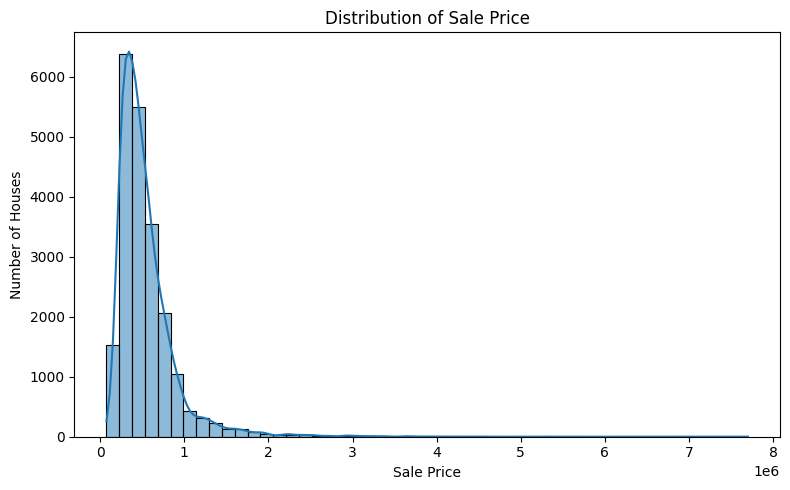

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    df["Sale Price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.show()

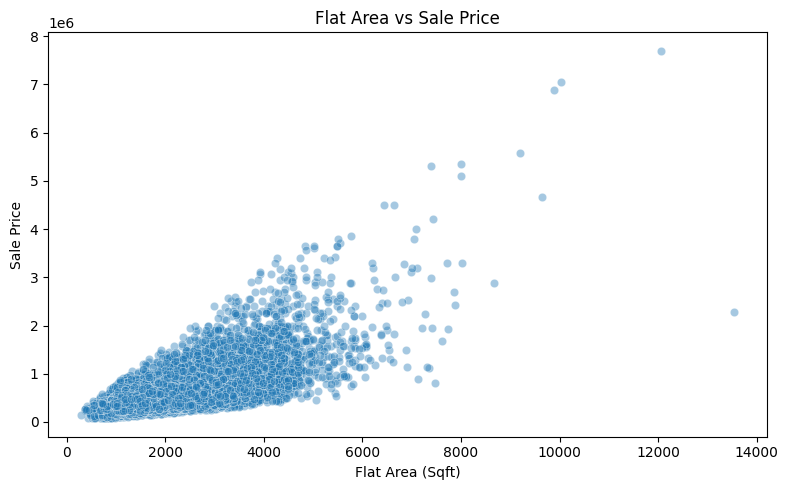

In [45]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Flat Area (in Sqft)",
    y="Sale Price",
    alpha=0.4
)

plt.title("Flat Area vs Sale Price")
plt.xlabel("Flat Area (Sqft)")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

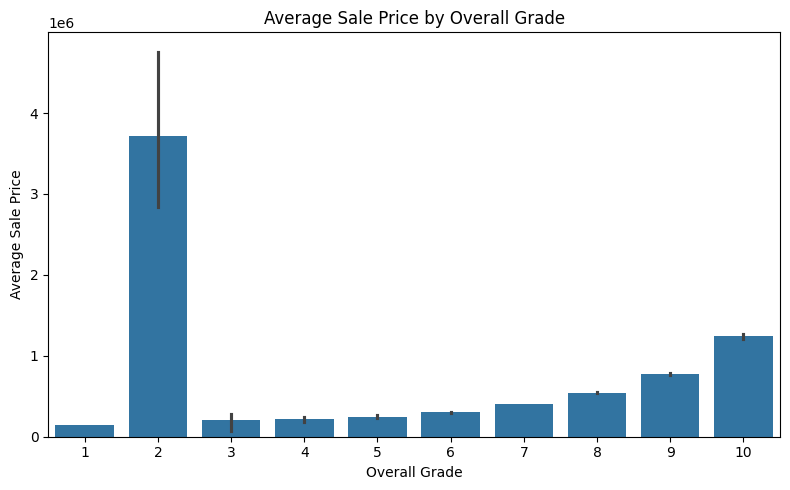

In [46]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Overall Grade",
    y="Sale Price",
    estimator="mean"
)

plt.title("Average Sale Price by Overall Grade")
plt.xlabel("Overall Grade")
plt.ylabel("Average Sale Price")
plt.tight_layout()
plt.show()

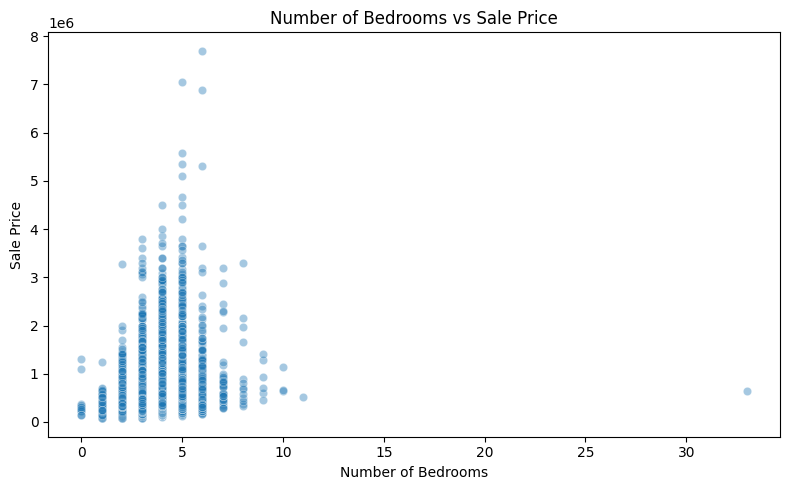

In [47]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="No of Bedrooms",
    y="Sale Price",
    alpha=0.4
)

plt.title("Number of Bedrooms vs Sale Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

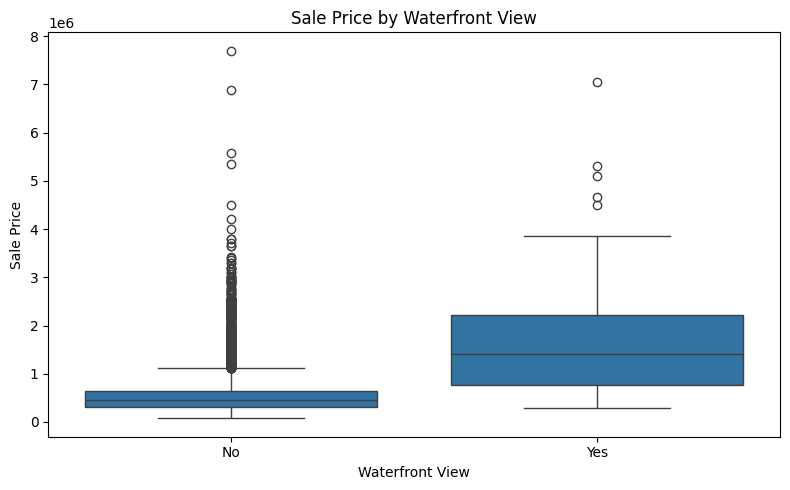

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Waterfront View",
    y="Sale Price"
)

plt.title("Sale Price by Waterfront View")
plt.xlabel("Waterfront View")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

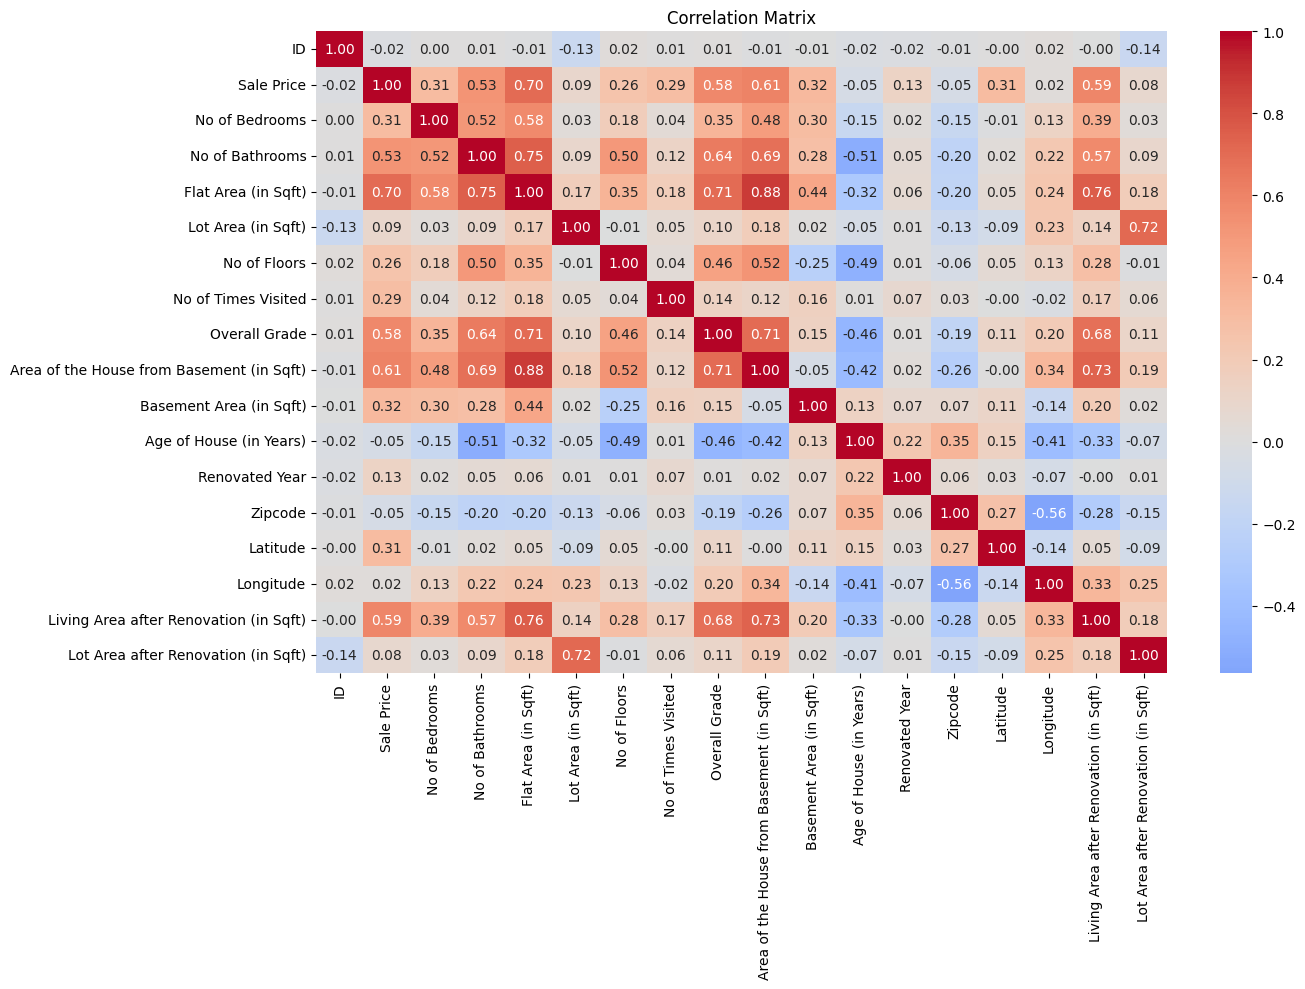

In [49]:
plt.figure(figsize=(14, 10))

corr_matrix = df.select_dtypes(
    include=["int64", "float64"]
).corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

Conclusion: The House Pricing dataset was preprocessed by removing duplicates, handling missing values, encoding categorical variables, analyzing numerical outliers using the IQR method, and standardizing numerical features. The dataset was divided into 80% training and 20% testing data, with Sale Price used as the target variable.